<a href="https://colab.research.google.com/github/vroos001/CYSE-635/blob/main/Module_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import **Pytorch** libraries and APIs.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import torchvision.datasets
from torch.utils.data import Subset
from torch.autograd import Variable
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

# define the function of displaying multiple images
def show_images(images) -> None:
    n: int = images.size(0)

    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        # Debug, plot figure
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.axis('off')

    plt.show(block=True)

# define the function of displaying multiple images
def show_images_withPred(images,label,pred,conf) -> None:
    n: int = images.size(0)

    f = plt.figure(figsize=(24, 6))
    for i in range(n):
        # Debug, plot figure
        f.add_subplot(1, n, i + 1)
        plt.imshow(images[i].cpu().squeeze(), cmap='gray')
        plt.title("{} -> {}".format(label[i], pred[i]))
        #plt.title("Conf:{} \n {} -> {}".format(conf[i][pred[i]]*100,label[i], pred[i]))
        plt.axis('off')

    plt.show(block=True)


In [2]:
# Hyperparameters and Data loaders
num_epochs = 10
num_classes = 10
batch_size = 256
learning_rate = 0.001


DATA_PATH = 'data/'
MODEL_STORE_PATH = 'models/'

# transforms to apply to the data
trans = transforms.Compose([transforms.ToTensor()])

# MNIST dataset
train_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=True, transform=trans, download=True)
test_dataset = torchvision.datasets.MNIST(root=DATA_PATH, train=False, transform=trans)

# Data loader
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, num_workers=4, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, num_workers=4, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 442kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.11MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [3]:
# CNN
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(1, -1),
        )
        self.fc1 = nn.Linear(7 * 7 * 16, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.dropout=nn.Dropout(0.3)

    def forward(self, x):
        out = self.features(x)
        out = self.dropout(self.fc1(out))
        out = self.dropout(self.fc2(out))
        out = self.fc3(out)

        return out


model=LeNet()
model.cuda()
model.train()

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [4]:
model.train()
loss_list_cnn = []
acc_list_cnn = []
total_step = len(train_loader)

for epoch in range(num_epochs):
  for i, (images, labels) in enumerate(train_loader):
    images = images.cuda()
    labels = labels.cuda()

    outputs = model(images)

    loss = criterion(outputs, labels)
    loss_list_cnn.append(loss.item())

    # Backprop and percform Adam optimisation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Track the accuracy
    total = labels.size(0)
    _, predicted = torch.max(outputs.data, 1)
    correct = (predicted == labels).sum().item()
    acc_list_cnn.append(correct / total)

    if (i%150 == 0):
      print('Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}, Accuracy: {:.2f}%'
              .format(epoch + 1, num_epochs, i, total_step, loss.item(),
                      (correct / total) * 100))


model.eval()
with torch.no_grad():
  correct = 0
  total = 0
  for images, labels in test_loader:
      images = images.cuda()
      labels = labels.cuda()

      outputs = model(images)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

print(
  'Accuracy of the model on the 10000 test images: {} %'.format((correct / total) * 100))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch [1/10], Step [0/235], Loss: 2.3173, Accuracy: 8.59%
Epoch [1/10], Step [150/235], Loss: 0.2850, Accuracy: 92.19%
Epoch [2/10], Step [0/235], Loss: 0.1898, Accuracy: 94.92%
Epoch [2/10], Step [150/235], Loss: 0.0689, Accuracy: 98.44%
Epoch [3/10], Step [0/235], Loss: 0.0794, Accuracy: 97.27%
Epoch [3/10], Step [150/235], Loss: 0.1215, Accuracy: 96.48%
Epoch [4/10], Step [0/235], Loss: 0.1055, Accuracy: 97.27%
Epoch [4/10], Step [150/235], Loss: 0.0772, Accuracy: 98.05%
Epoch [5/10], Step [0/235], Loss: 0.0567, Accuracy: 98.44%
Epoch [5/10], Step [150/235], Loss: 0.0512, Accuracy: 98.44%
Epoch [6/10], Step [0/235], Loss: 0.0590, Accuracy: 98.44%
Epoch [6/10], Step [150/235], Loss: 0.0337, Accuracy: 98.83%
Epoch [7/10], Step [0/235], Loss: 0.0530, Accuracy: 98.44%
Epoch [7/10], Step [150/235], Loss: 0.0534, Accuracy: 98.83%
Epoch [8/10], Step [0/235], Loss: 0.0888, Accuracy: 97.27%
Epoch [8/10], Step [150/235], Loss: 0.0615, Accuracy: 98.44%
Epoch [9/10], Step [0/235], Loss: 0.1224,

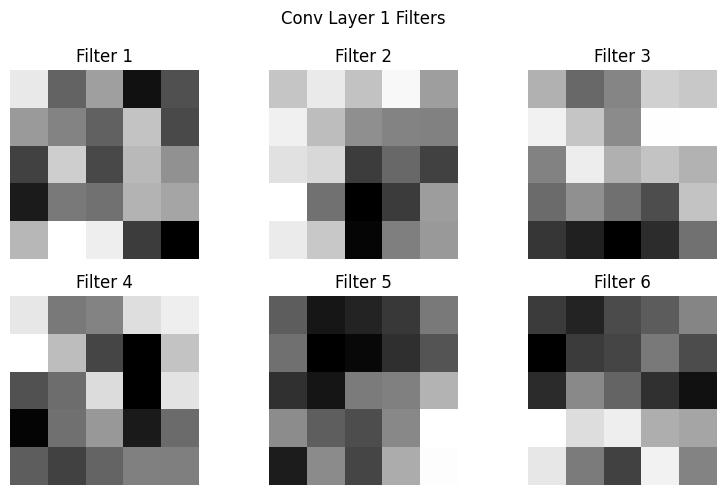

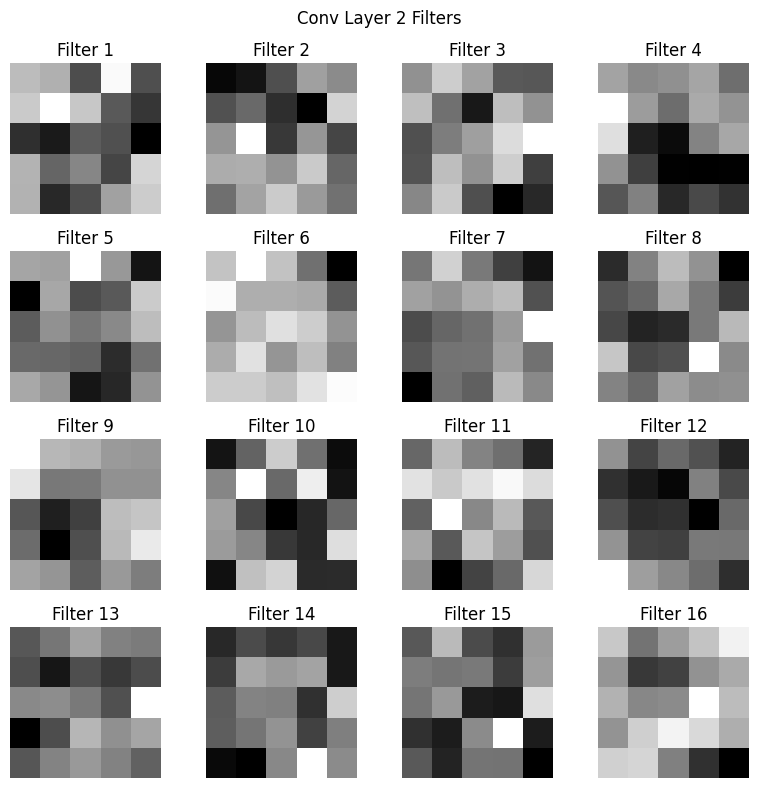

In [5]:
# Visualize filters from the first convolutional layer
conv1_filters = model.features[0].weight.detach().cpu()

fig, axes = plt.subplots(2, 3, figsize=(8, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(conv1_filters[i, 0], cmap='gray')
    ax.set_title(f'Filter {i + 1}')
    ax.axis('off')

plt.suptitle('Conv Layer 1 Filters')
plt.tight_layout()
plt.show()

# Visualize filters from the second convolutional layer
conv2_filters = model.features[3].weight.detach().cpu()

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    filter_image = conv2_filters[i].mean(dim=0)
    ax.imshow(filter_image, cmap='gray')
    ax.set_title(f'Filter {i + 1}')
    ax.axis('off')

plt.suptitle('Conv Layer 2 Filters')
plt.tight_layout()
plt.show()

Incorrect Predictions:


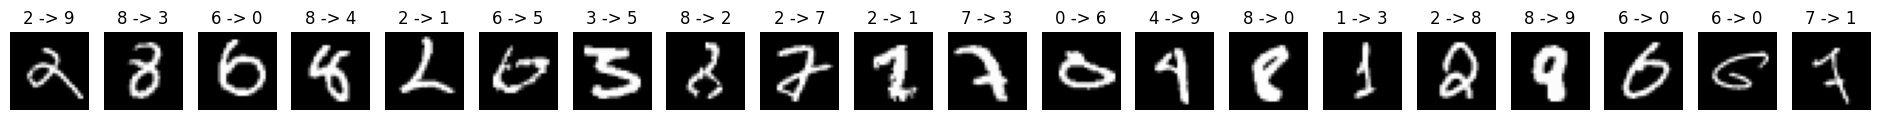

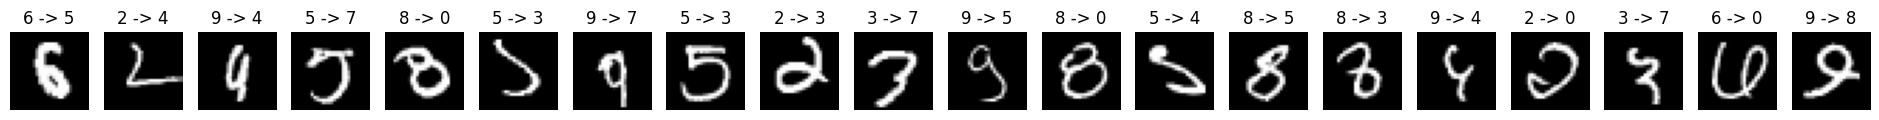

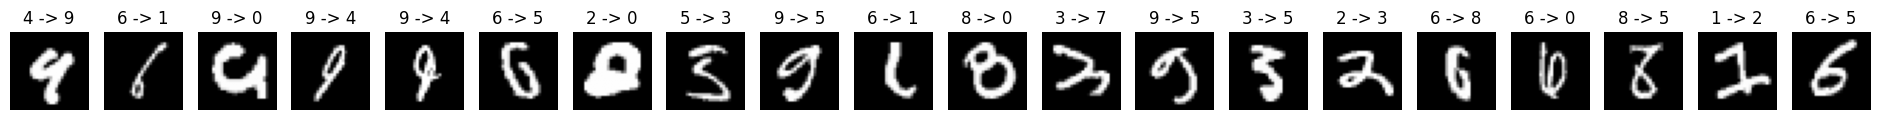

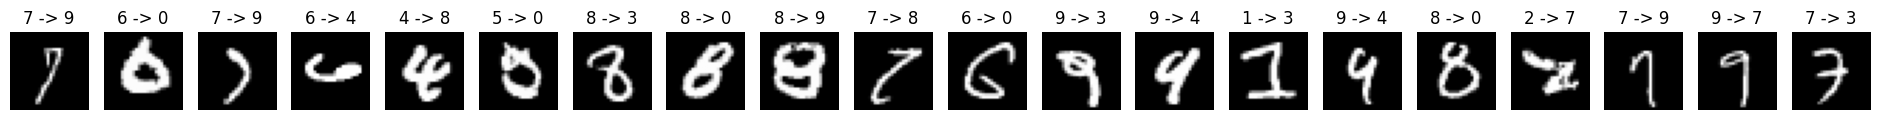



Correct Predictions:


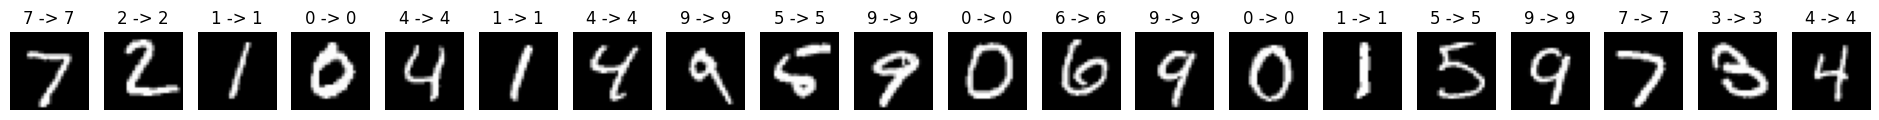

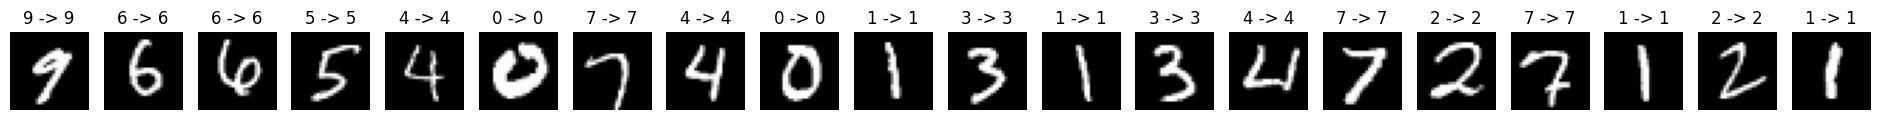

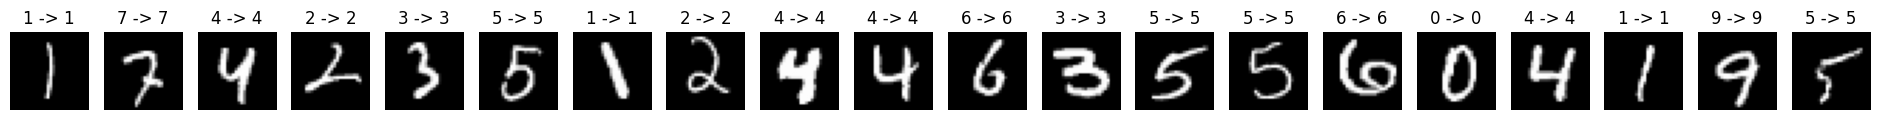

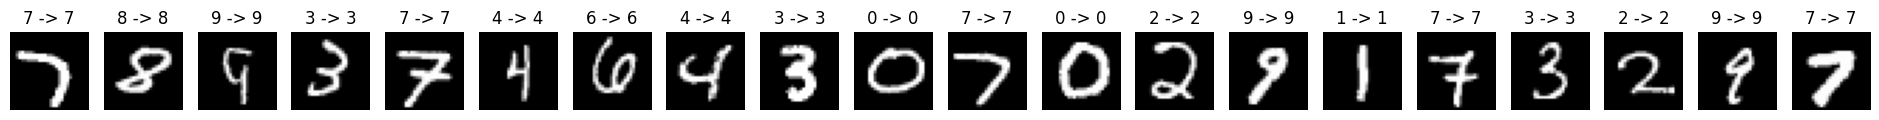

In [6]:
model.eval()
with torch.no_grad():
    correct = 0
    total = 0
    for i, (images, labels) in enumerate(test_loader):
        images = images.cuda()
        labels = labels.cuda()

        outputs = model(images)
        confidences = outputs.softmax(1)
        _, predicted = torch.max(outputs.data, 1)
        correct_idx = predicted == labels
        incorrect_idx = predicted != labels

        if i == 0:
            correct_images = images[correct_idx]
            correct_labels = labels[correct_idx]
            correct_pred = predicted[correct_idx]
            correct_conf = confidences[correct_idx]

            incorrect_images = images[incorrect_idx]
            incorrect_labels = labels[incorrect_idx]
            incorrect_pred = predicted[incorrect_idx]
            incorrect_conf = confidences[incorrect_idx]
        else:
            correct_images = torch.cat((correct_images, images[correct_idx]), 0)
            correct_labels = torch.cat((correct_labels, labels[correct_idx]), 0)
            correct_pred = torch.cat((correct_pred, predicted[correct_idx]), 0)
            correct_conf = torch.cat((correct_conf, confidences[correct_idx]), 0)

            incorrect_images = torch.cat((incorrect_images, images[incorrect_idx]), 0)
            incorrect_labels = torch.cat((incorrect_labels, labels[incorrect_idx]), 0)
            incorrect_pred = torch.cat((incorrect_pred, predicted[incorrect_idx]), 0)
            incorrect_conf = torch.cat((incorrect_conf, confidences[incorrect_idx]), 0)

print("Incorrect Predictions:")
plt_num = 20
for i in range(4):
    show_images_withPred(
        incorrect_images[i*plt_num:(i+1)*plt_num],
        incorrect_labels[i*plt_num:(i+1)*plt_num],
        incorrect_pred[i*plt_num:(i+1)*plt_num],
        incorrect_conf[i*plt_num:(i+1)*plt_num]
    )

print("\n\nCorrect Predictions:")
for i in range(4):
    show_images_withPred(
        correct_images[i*plt_num:(i+1)*plt_num],
        correct_labels[i*plt_num:(i+1)*plt_num],
        correct_pred[i*plt_num:(i+1)*plt_num],
        correct_conf[i*plt_num:(i+1)*plt_num]
    )

# Freeing memory by deleting large tensors after usage
del correct_images, correct_labels, correct_pred, correct_conf
del incorrect_images, incorrect_labels, incorrect_pred, incorrect_conf


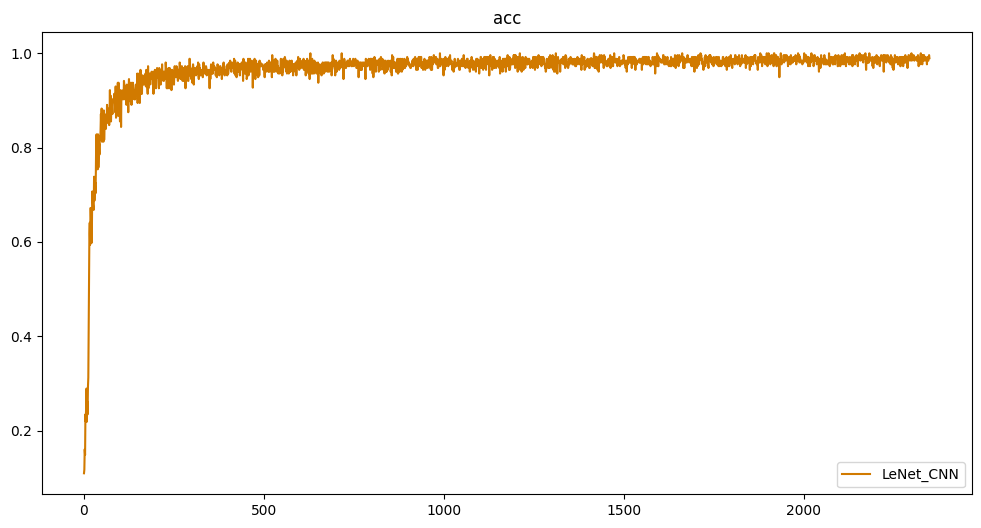

Text(0.5, 1.0, 'loss')

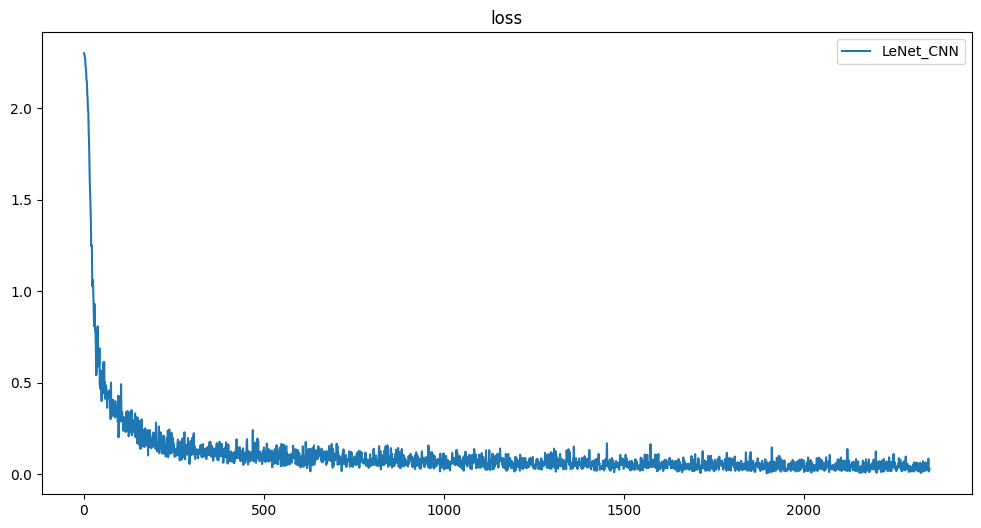

In [ ]:
plt.figure(figsize=(12, 6))
# plt.plot(acc_list, color='#1A62AE')  # DNN color: Blue
plt.plot(acc_list_cnn, color='#D17A00')  # LeNet_CNN color: Orange
# plt.legend(['DNN', 'LeNet_CNN'])
plt.legend(['LeNet_CNN'])
plt.title('acc')
plt.show()


plt.figure(figsize=(12,6))
# plt.plot(loss_list)
plt.plot(loss_list_cnn)
# plt.legend(['DNN','LeNet_CNN'])
plt.legend(['LeNet_CNN'])
plt.title('loss')

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


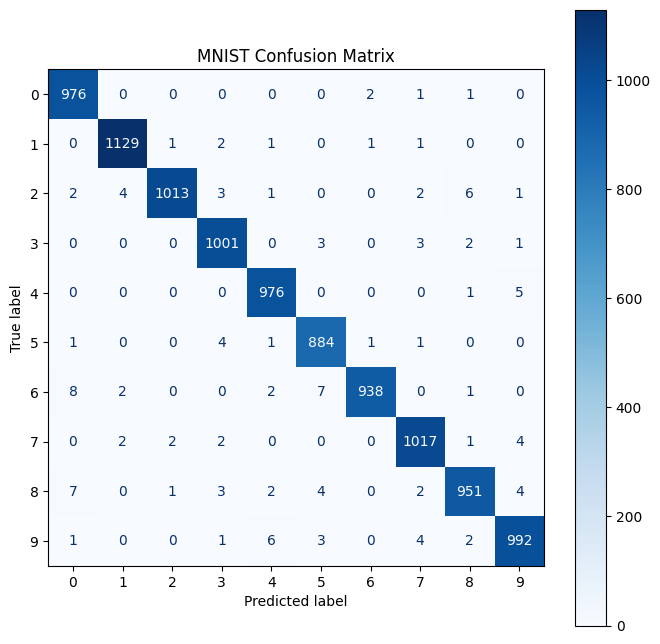

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.cuda()
        labels = labels.cuda()

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("MNIST Confusion Matrix")
plt.show()

# **Homework**
